In [1]:
from microtorch.model_maker import ModelMaker
from microtool.microtorch import MicrotorchTissueModel
from microtool.tissue_model import MultiTissueModel, RelaxationTissueModel
from microtool.utils.unit_registry import unit

microtorch_model = ModelMaker("Ball")





# Wrap each compartment individually, not the combined ModelMaker model.

ball_model = MicrotorchTissueModel(
    microtorch_model,
    parameters={"D": 2},
)



ball_relax = RelaxationTissueModel(ball_model, t2=50e-3 * unit("s"))


ball_model = ball_relax
ball_model["model_D"].optimize = True
ball_model["model_D"].fit_flag = True
ball_model["model_D"].scale = 1
#ball_model["model_D"].value_list = [1.5, 1.6, 1.7, 1.8, 1.9, 2, 2.1, 2.2, 2.3, 2.4, 2.5]

ball_model["S0"].optimize = True
ball_model["S0"].fit_flag = True

ball_model["T2"].optimize = True
ball_model["T2"].fit_flag = True
ball_model["T2"].value_list = [0.04, 0.05, 0.06]

print(ball_relax)

No YAML configuration found for Ball model.
Falling back to parsing model name for compartments: ['Ball'].
Parameter ranges will be the default compartment values.
-----------
########### Making model:  Ball
########### Compartments: ['Ball']
########### Parameter names: [['D']]
########### Parameter ranges: [[[0.001, 3]]]
-----------
Tissue model with 3 scalar parameters:
Tissue-parameter      Value    Scale  Optimize    Fit    Fit Bounds
------------------  -------  -------  ----------  -----  -------------
model_D                2       1      True        True   (0.001, 3.0)
T2                     0.05    0.001  True        True   (0.0001, 1.0)
S0                     1       1      True        True   (0.0, 2.0)


In [2]:
import numpy as np
from microtool.acquisition_scheme import DiffusionAcquisitionScheme
from microtool.gradient_sampling import sample_uniform_half_sphere

n_directions = 6
n_shells = 4
block_size = n_directions + 1  # b0 + n_directions

shell_bvals = [200, 354, 500, 500, 800, 900]
shell_deltas = [0.0114, 0.0105, 0.02, 0.02, 0.02, .02]
shell_Deltas = [0.0222, 0.0212, 0.03, 0.03, 0.03, 0.03]
initial_te = [0.09, 0.04, 0.06, 0.06, 0.07, 0.09]

# Build the measurements in shell blocks: b0, then six directions.
b_vals_list = []
pulse_durations_list = []
pulse_intervals_list = []
echo_times_list = []

for i in range(n_shells):
    b_vals_list.append(0.0)
    b_vals_list.extend([shell_bvals[i]] * n_directions)

    pulse_durations_list.extend([shell_deltas[i]] * block_size)
    pulse_intervals_list.extend([shell_Deltas[i]] * block_size)
    echo_times_list.extend([initial_te[i]] * block_size)

b_vals = np.array(b_vals_list)
pulse_durations = np.array(pulse_durations_list)
pulse_intervals = np.array(pulse_intervals_list)
echo_times = np.array(echo_times_list)
directions = sample_uniform_half_sphere(len(b_vals))

initial_scheme = DiffusionAcquisitionScheme.from_bvals(
    b_values=b_vals,
    b_vectors=directions,
    pulse_durations=pulse_durations,
    pulse_intervals=pulse_intervals,
    echo_times=echo_times,
)


# TE and timing: one free value for each 7-measurement shell block.
for name in (
    "EchoTime",
    "DiffusionPulseDuration",
    "DiffusionPulseInterval",
):
    initial_scheme[name].set_repetition_period(block_size)

# Gradient magnitude: fix b0, then share one value across each shell's six DW measurements.
b0_mask = b_vals == 0
magnitude = initial_scheme["DiffusionPulseMagnitude"]
magnitude.set_fixed_mask(b0_mask)
magnitude.set_repetition_period(n_directions)

print("TE free indices:",
      np.flatnonzero(initial_scheme["EchoTime"].optimize_mask))
print("Timing free indices:",
      np.flatnonzero(initial_scheme["DiffusionPulseDuration"].optimize_mask))
print("Gradient free indices:",
      np.flatnonzero(magnitude.optimize_mask))

print(initial_scheme)


TE free indices: [ 0  7 14 21]
Timing free indices: [ 0  7 14 21]
Gradient free indices: [ 1  8 15 22]
Acquisition scheme with 28 measurements and 6 scalar parameters. 
total number of optimized parameters is 16:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.078)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.01, 0.1)    DiffusionPulseInterval [s] in (0.01, 0.1)    EchoTime [s] in (0.01, 0.1)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  -------------------------------------------  -------------------------------------------  -----------------------------
                                       -0                                          2.24761                                       0.982258                                       0.0114                                       0.0222                           0.09
          

In [3]:
signal = ball_model(initial_scheme)
print(signal)

[0.16529889 0.11080316 0.11080316 0.11080316 0.11080316 0.11080316
 0.11080316 0.44932896 0.22135223 0.22135223 0.22135223 0.22135223
 0.22135223 0.22135223 0.30119421 0.11080316 0.11080316 0.11080316
 0.11080316 0.11080316 0.11080316 0.30119421 0.11080316 0.11080316
 0.11080316 0.11080316 0.11080316 0.11080316]


In [4]:
jacobian = ball_model.scaled_jacobian(initial_scheme)
print(jacobian)



[[ 0.          0.00595076  0.16529889]
 [-0.02216063  0.00398891  0.11080316]
 [-0.02216063  0.00398891  0.11080316]
 [-0.02216063  0.00398891  0.11080316]
 [-0.02216063  0.00398891  0.11080316]
 [-0.02216063  0.00398891  0.11080316]
 [-0.02216063  0.00398891  0.11080316]
 [ 0.          0.00718926  0.44932896]
 [-0.07835869  0.00354164  0.22135223]
 [-0.07835869  0.00354164  0.22135223]
 [-0.07835869  0.00354164  0.22135223]
 [-0.07835869  0.00354164  0.22135223]
 [-0.07835869  0.00354164  0.22135223]
 [-0.07835869  0.00354164  0.22135223]
 [ 0.          0.00722866  0.30119421]
 [-0.05540158  0.00265928  0.11080316]
 [-0.05540158  0.00265928  0.11080316]
 [-0.05540158  0.00265928  0.11080316]
 [-0.05540158  0.00265928  0.11080316]
 [-0.05540158  0.00265928  0.11080316]
 [-0.05540158  0.00265928  0.11080316]
 [ 0.          0.00722866  0.30119421]
 [-0.05540158  0.00265928  0.11080316]
 [-0.05540158  0.00265928  0.11080316]
 [-0.05540158  0.00265928  0.11080316]
 [-0.05540158  0.00265928

/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/torch/autograd/graph.py:1113: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12020). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


In [5]:
import copy
from microtool.optimize import optimize_scheme



solver_options = {
    "verbose": 2,
    "maxiter": 250,
    "finite_diff_rel_step": 1e-4,
    # "initial_tr_radius": 0.05
}


optimal_scheme_initial, res = optimize_scheme(
        initial_scheme,
        ball_model,
        noise_variance=0.02,
        method="trust-constr",
        solver_options=solver_options,
    )


| niter |f evals|CG iter|  obj func   |tr radius |   opt    |  c viol  |
|-------|-------|-------|-------------|----------|----------|----------|
|   1   |  17   |   0   | +5.2868e+02 | 1.00e+00 | 2.24e+01 | 0.00e+00 |


/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/scipy/optimize/_differentiable_functions.py:737: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(delta_x, delta_g)


|   2   |  34   |   1   | +4.2730e+02 | 7.00e+00 | 2.22e+01 | 0.00e+00 |
|   3   |  51   |  17   | +3.6760e+02 | 2.35e+01 | 1.86e+01 | 0.00e+00 |
|   4   |  68   |  33   | +3.0786e+02 | 2.35e+01 | 1.47e+01 | 0.00e+00 |
|   5   |  85   |  49   | +2.7637e+02 | 2.35e+01 | 1.28e+01 | 0.00e+00 |
|   6   |  102  |  65   | +2.5621e+02 | 2.35e+01 | 1.29e+01 | 0.00e+00 |
|   7   |  119  |  81   | +2.4515e+02 | 2.35e+01 | 1.47e+01 | 0.00e+00 |
|   8   |  136  |  94   | +2.4336e+02 | 2.35e+01 | 1.36e+01 | 0.00e+00 |
|   9   |  153  |  110  | +2.4109e+02 | 2.35e+01 | 1.36e+01 | 0.00e+00 |
|  10   |  170  |  126  | +2.3966e+02 | 2.35e+01 | 1.36e+01 | 0.00e+00 |
|  11   |  187  |  132  | +2.3938e+02 | 2.35e+01 | 1.36e+01 | 0.00e+00 |
|  12   |  204  |  148  | +2.3854e+02 | 2.35e+01 | 1.38e+01 | 0.00e+00 |
|  13   |  221  |  164  | +2.3805e+02 | 2.35e+01 | 1.41e+01 | 0.00e+00 |
|  14   |  238  |  180  | +2.3650e+02 | 2.35e+01 | 1.51e+01 | 0.00e+00 |
|  15   |  255  |  196  | +2.3142e+02 | 2.35e+01 | 

KeyboardInterrupt: 

In [ ]:
# import microtool.optimize.methods as methods
# from microtool.optimize import optimize_scheme

# import numpy as np
# from microtool.optimize.loss_functions import compute_loss, gauss_loss


# method = methods.SOMA()
# optimal_scheme_SOMA, _ = optimize_scheme(
#     initial_scheme, ball_model, noise_variance=0.02, method=method
# )

In [ ]:
print(optimal_scheme_initial)
print(optimal_scheme_initial.b_values)

# print(optimal_scheme_SOMA)
# print(optimal_scheme_SOMA.b_values)


Acquisition scheme with 28 measurements and 6 scalar parameters. 
total number of optimized parameters is 16:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.078)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.01, 0.1)    DiffusionPulseInterval [s] in (0.01, 0.1)    EchoTime [s] in (0.01, 0.1)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  -------------------------------------------  -------------------------------------------  -----------------------------
                                     -0                                            2.24761                                       0.982258                                    0.0110012                                    0.0436485                      0.0918002
                                      0.000498416                                 -1.25047                       

In [ ]:
print(ball_model(optimal_scheme_initial))


# print(ball_model(optimal_scheme_SOMA))

[0.15945336 0.15942591 0.15942591 0.15942591 0.15942591 0.15942591
 0.15942591 0.54539517 0.50603923 0.50603923 0.50603923 0.50603923
 0.50603923 0.50603923 0.15941721 0.15938726 0.15938726 0.15938726
 0.15938726 0.15938726 0.15938726 0.19620529 0.13816479 0.13816479
 0.13816479 0.13816479 0.13816479 0.13816479]


In [ ]:
from microtool.monte_carlo.simulation import MonteCarloSimulation
from scipy import stats


# loc is mean and scale is standard deviation
noise_distribution = stats.norm(loc=0, scale=0.02)

# Perform a Monte Carlo simulation using the initial scheme.
simulation = MonteCarloSimulation(
    initial_scheme,
    ball_model,
    noise_distribution,
    n_sim=1000,
    fit_options={"diff_step": 1e-4},
)
simulation.run()
initial = simulation.result

# Repeat the simulation using the optimized scheme.
simulation.set_scheme(optimal_scheme_initial)
simulation.run()
optimal = simulation.result

Starting Monte Carlo with 1000 simulations: 100%|██████████| 1000/1000 [00:04<00:00, 223.09it/s]


Valid fits: initial=1000, optimal=1000

Initial scheme
             bias      std     RMSE  scaled bias  scaled std  scaled RMSE
model_D -0.00664  0.10687  0.10708     -0.00332     0.05344      0.05354
T2       0.00032  0.00345  0.00347      0.00635     0.06904      0.06933
S0      -0.00076  0.07919  0.07919     -0.00076     0.07919      0.07919 
TOTAL scaled RMSE: 0.06818

Optimal scheme
             bias      std     RMSE  scaled bias  scaled std  scaled RMSE
model_D -0.00443  0.36547  0.36550     -0.00221     0.18274      0.18275
T2       0.00007  0.00135  0.00135      0.00132     0.02699      0.02702
S0      -0.00011  0.02864  0.02864     -0.00011     0.02864      0.02864 
TOTAL scaled RMSE: 0.10793

Improvement of total scaled RMSE: -58.3%


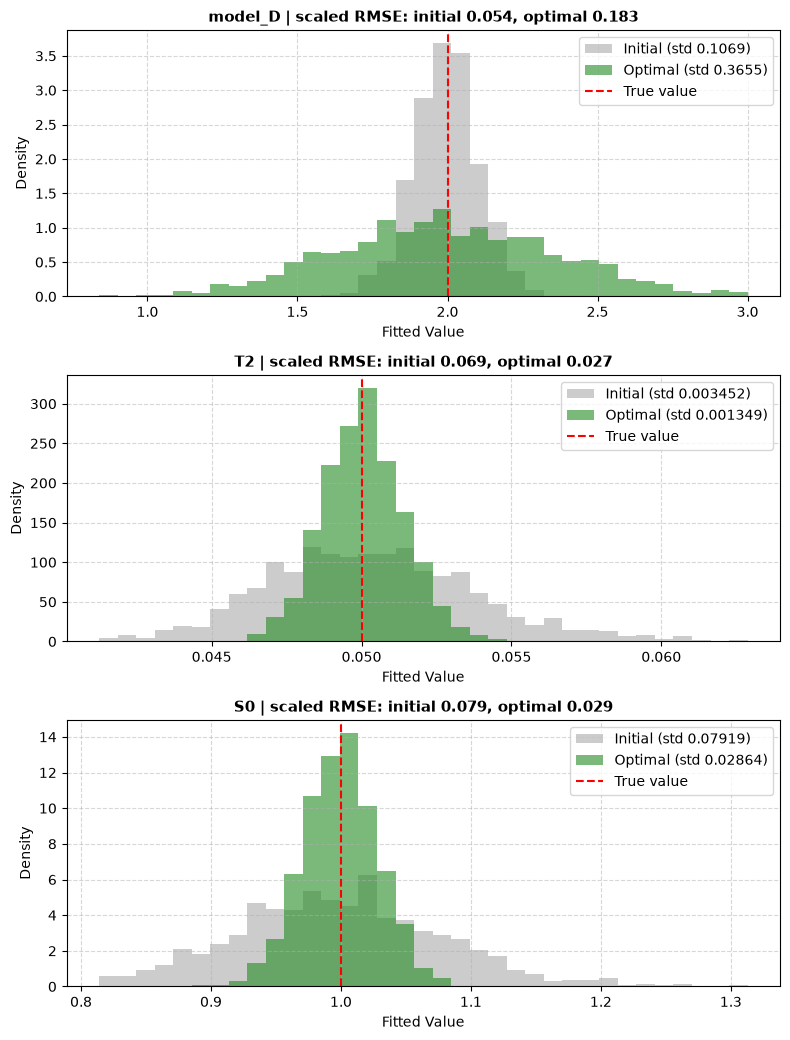

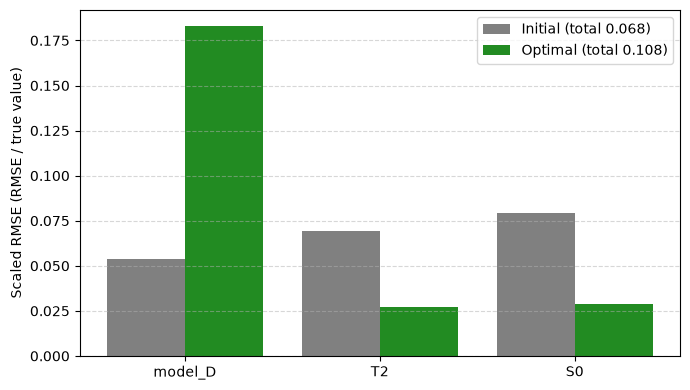

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ data
df_init = pd.DataFrame(initial)
df_opt = pd.DataFrame(optimal)

# ground truth used for the simulation (same units as the fitted columns)
true_values = {
    "model_D": 2.0,     # 1e-9 m²/s
    "T2":      0.050,   # seconds
    "S0":      1.0,
}
scales = dict(true_values)   # relative RMSE = RMSE / true value

common_cols = [c for c in df_opt.columns if c in df_init.columns and c in true_values]
missing = [c for c in df_opt.columns if c in df_init.columns and c not in true_values]
if missing:
    print(f"Skipping columns without a true value: {missing}")

# drop failed fits (NaN / inf)
df_init = df_init[common_cols].replace([np.inf, -np.inf], np.nan).dropna()
df_opt = df_opt[common_cols].replace([np.inf, -np.inf], np.nan).dropna()
print(f"Valid fits: initial={len(df_init)}, optimal={len(df_opt)}")


# ------------------------------------------------------------------ RMSE
def rmse_table(df):
    rows = {}
    for col in common_cols:
        err = df[col].to_numpy() - true_values[col]
        rmse = np.sqrt(np.mean(err ** 2))
        s = abs(scales[col])
        rows[col] = {
            "bias": err.mean(),
            "std": err.std(),
            "RMSE": rmse,
            "scaled bias": err.mean() / s,
            "scaled std": err.std() / s,
            "scaled RMSE": rmse / s,
        }
    tab = pd.DataFrame(rows).T
    total = np.sqrt(np.mean(tab["scaled RMSE"] ** 2))
    return tab, total


tab_init, total_init = rmse_table(df_init)
tab_opt, total_opt = rmse_table(df_opt)

print("\nInitial scheme\n", tab_init.round(5), f"\nTOTAL scaled RMSE: {total_init:.5f}")
print("\nOptimal scheme\n", tab_opt.round(5), f"\nTOTAL scaled RMSE: {total_opt:.5f}")
print(f"\nImprovement of total scaled RMSE: {100 * (1 - total_opt / total_init):.1f}%")

# ------------------------------------------------------------------ histograms
fig, axes = plt.subplots(
    nrows=len(common_cols), ncols=1, figsize=(8, 3.5 * len(common_cols)), squeeze=False
)

for i, col in enumerate(common_cols):
    ax = axes[i, 0]

    # shared bin edges so both histograms are directly comparable
    both = np.concatenate([df_init[col].to_numpy(), df_opt[col].to_numpy()])
    bins = np.linspace(both.min(), both.max(), 36)

    ax.hist(df_init[col], bins=bins, density=True, alpha=0.4, color="gray",
            label=f"Initial (std {tab_init.loc[col, 'std']:.4g})")
    ax.hist(df_opt[col], bins=bins, density=True, alpha=0.6, color="forestgreen",
            label=f"Optimal (std {tab_opt.loc[col, 'std']:.4g})")
    ax.axvline(true_values[col], color="red", linestyle="--", label="True value")

    ax.set_title(
        f"{col} | scaled RMSE: initial {tab_init.loc[col, 'scaled RMSE']:.3f}, "
        f"optimal {tab_opt.loc[col, 'scaled RMSE']:.3f}",
        fontsize=11, fontweight="bold",
    )
    ax.set_xlabel("Fitted Value")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------ bar plot
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(common_cols))
ax.bar(x - 0.2, tab_init["scaled RMSE"], 0.4, color="gray",
       label=f"Initial (total {total_init:.3f})")
ax.bar(x + 0.2, tab_opt["scaled RMSE"], 0.4, color="forestgreen",
       label=f"Optimal (total {total_opt:.3f})")
ax.set_xticks(x)
ax.set_xticklabels(common_cols)
ax.set_ylabel("Scaled RMSE (RMSE / true value)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5, axis="y")
plt.tight_layout()
plt.show()